# Dynamic-tropopause diagnosis of the March 2026 block, following Davis (2026)

`CA_2026_upstream_mechanism_composite.ipynb` (the first upstream look) composited
fixed-pressure-level fields (Z300/jet speed/SST/IVT) across the four WY2026 episodes
and found a real but modest signature -- CA-box Z300 highest and domain-mean jet speed
lowest during the record March episode -- but no clean omega-block shape, and an IVT
result that actively pointed away from a moisture-driven story.

Reading `~/ERA5/March_2026_Western-US-Heat Wave.pdf` (Chris Davis, UMass Amherst/NCAR,
June 2026 -- the source analysis this project's framing is built on) shows why that
first attempt was too blunt an instrument: the paper's own method uses the **dynamic
tropopause (DT, the 2-PVU surface)**, not a fixed pressure level, because the whole
point of an anomalously amplified ridge is that it pushes the tropopause to very
different pressures in different places -- a fixed 300 hPa slice cuts through the
stratosphere in some columns and the mid-troposphere in others during a strong block,
which is exactly the kind of structure a fixed-level composite would blur or miss. The
paper's own key findings, reproduced here as a target:

- An **upstream blocking anticyclone over the NW Pacific** (an omega block "at times")
  created an anomalously **strong subtropical jet** -- not a weakened jet overall, as
  my first composite's domain-mean suggested; that mean likely blended a strengthened
  subtropical branch with a weakened midlatitude branch into one misleading number.
- The local CA block was **reinforced by impinging eddies**, not sustained by their
  absence.
- The Hovmoller diagram of meridional wind and potential-temperature deviation on the
  DT, 25-45N, shows the block as a near-stationary, locked-in feature for the March
  11-20 window.

**What this notebook does:** extracts PV, T, U, V across an 11-level bracket
(500-50 hPa, `get_upstream_pv_theta.py`), locates the 2-PVU dynamic tropopause at
every grid column by interpolation, and reproduces the paper's two clearest
diagnostics -- a theta-on-DT map and a DT Hovmoller diagram -- for all four WY2026
episodes, not just the one already known to be exceptional.

**What this notebook does not attempt:** the paper's backward-trajectory and
PV-non-conservation cross-section analysis (Figs. 9-12) require a trajectory
integration scheme this project doesn't have yet -- flagged as future work, not
attempted here.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
PV_THRESH = 2.0  # PVU, standard dynamic-tropopause definition


## 1. Reproduce the four WY2026 Z500 episodes

Same reproduction as the companion composite notebook -- not hardcoded, so this can't
silently drift from `CA_z500_t700_blocking_events_detrend_5day.ipynb` Section 8's own
numbers.

In [2]:
YEARS = list(range(1990, 2026))
CLIM_WINDOW, MIN_DURATION, MAX_GAP, SIGN = 5, 5, 1, 1

files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW,
                                          label='z500', verbose=False)

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
df26['z500_sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                 min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes = z500_episodes[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']
z500_episodes

ERROR 1: PROJ: proj_create_from_database: Open of /glade/work/mingge/conda-envs/my_npl2026a/share/proj failed


,start_date,end_date,duration_days,peak_sanom,label
0,2026-01-10,2026-01-18,9,1.861270,Jan episode
1,2026-01-29,2026-02-05,8,1.885298,Late Jan/Feb episode
2,2026-02-23,2026-03-01,7,1.935595,Late Feb episode
3,2026-03-11,2026-03-29,19,2.715996,March (record) episode


## 2. Load PV/T/U/V and locate the dynamic tropopause

The DT-crossing search walks upward (500 -> 50 hPa) at every (time, lat, lon) column
and linearly interpolates pressure and each field to the first level where PV reaches
2.0 PVU -- the standard dynamic-tropopause definition. Validated on synthetic test
columns (exact-crossing, interpolated-crossing, and never-crosses cases) before being
applied here.

**Limitation:** this takes the *first* upward crossing only, with no requirement that PV
stay above 2.0 PVU afterward. Davis's own paper describes exactly the condition that can
break a single-crossing search -- diabatic heating reducing PV within the upper-level
frontal zone -- which could produce a shallow, non-persistent PV excursion below the real
tropopause in precisely the ridge region this notebook studies. Not expected to be common,
but not checked for here; a more robust version would require the crossing to hold for N
levels above threshold, not just the first one.

In [3]:
ds_pv = xr.open_dataset(DATA_DIR / 'upstream_pv_theta_2026.nc', engine='netcdf4')
LEVELS = ds_pv.level.values  # already descending pressure / ascending altitude order
print('levels (hPa):', LEVELS)

pv_pvu = ds_pv.pv.values * 1e6  # K m^2 kg^-1 s^-1 -> PVU
theta = ds_pv.t.values * (1000.0 / ds_pv.level.values[None, :, None, None]) ** 0.286


def dynamic_tropopause(pv, levels, fields, pv_thresh=2.0, level_axis=0):
    """pv: array with `level_axis` matching `levels` (descending pressure / ascending
    altitude). fields: dict name->array, same shape as pv. Returns dict of
    level-axis-collapsed arrays: 'pressure' plus each field, interpolated to the
    first upward crossing of pv_thresh; NaN where PV never reaches pv_thresh within
    the level bracket."""
    pv = np.moveaxis(pv, level_axis, 0)
    fields = {k: np.moveaxis(v, level_axis, 0) for k, v in fields.items()}
    levels = np.asarray(levels, dtype=float)

    above = pv >= pv_thresh
    any_above = above.any(axis=0)
    idx_first = above.argmax(axis=0)
    idx_below = np.clip(idx_first - 1, 0, None)
    already_above_bottom = any_above & (idx_first == 0)

    def gather(arr, idx):
        return np.take_along_axis(arr, idx[None, ...], axis=0)[0]

    pv_below, pv_above = gather(pv, idx_below), gather(pv, idx_first)
    denom = pv_above - pv_below
    frac = np.where(denom != 0, (pv_thresh - pv_below) / np.where(denom == 0, 1, denom), 0.0)
    frac = np.clip(frac, 0.0, 1.0)
    frac = np.where(already_above_bottom, 0.0, frac)

    level_grid = np.broadcast_to(levels[(slice(None),) + (None,) * (pv.ndim - 1)], pv.shape)
    lvl_below, lvl_above = gather(level_grid, idx_below), gather(level_grid, idx_first)
    p_dt = np.where(any_above, lvl_below + frac * (lvl_above - lvl_below), np.nan)

    out = {'pressure': p_dt}
    for name, arr in fields.items():
        f_below, f_above = gather(arr, idx_below), gather(arr, idx_first)
        out[name] = np.where(any_above, f_below + frac * (f_above - f_below), np.nan)
    out['no_crossing_frac'] = float((~any_above).mean())
    out['below_bottom_frac'] = float(already_above_bottom.mean())
    return out


dt = dynamic_tropopause(pv_pvu, LEVELS, {'theta': theta, 'u': ds_pv.u.values, 'v': ds_pv.v.values},
                         pv_thresh=PV_THRESH, level_axis=1)  # level_axis=1 since shape is (time, level, lat, lon)
print(f'No-crossing fraction (DT above 50 hPa, excluded from this analysis): '
      f'{dt["no_crossing_frac"]*100:.2f}% of all time-lat-lon points')
print(f'Below-bottom fraction (DT below 500 hPa, degenerate edge case): '
      f'{dt["below_bottom_frac"]*100:.3f}%')

theta_dt = xr.DataArray(dt['theta'], dims=('time', 'latitude', 'longitude'),
                         coords={'time': ds_pv.time, 'latitude': ds_pv.latitude, 'longitude': ds_pv.longitude})
u_dt = xr.DataArray(dt['u'], dims=('time', 'latitude', 'longitude'), coords=theta_dt.coords)
v_dt = xr.DataArray(dt['v'], dims=('time', 'latitude', 'longitude'), coords=theta_dt.coords)
p_dt = xr.DataArray(dt['pressure'], dims=('time', 'latitude', 'longitude'), coords=theta_dt.coords)
wind_dt = np.sqrt(u_dt**2 + v_dt**2)

levels (hPa): [500. 400. 300. 250. 200. 175. 150. 125. 100.  70.  50.]


No-crossing fraction (DT above 50 hPa, excluded from this analysis): 0.00% of all time-lat-lon points
Below-bottom fraction (DT below 500 hPa, degenerate edge case): 0.405%


## 3. Theta-on-DT maps, all four episodes

Same style as the paper's own DT maps: filled contours of potential temperature on
the dynamic tropopause, with wind-speed contours overlaid. A high, amplified ridge
should show up as a northward bulge of warm (high-theta) air on the DT, exactly the
shape in the paper's own Figure (`Huge Ridge Develops over the West Coast`).

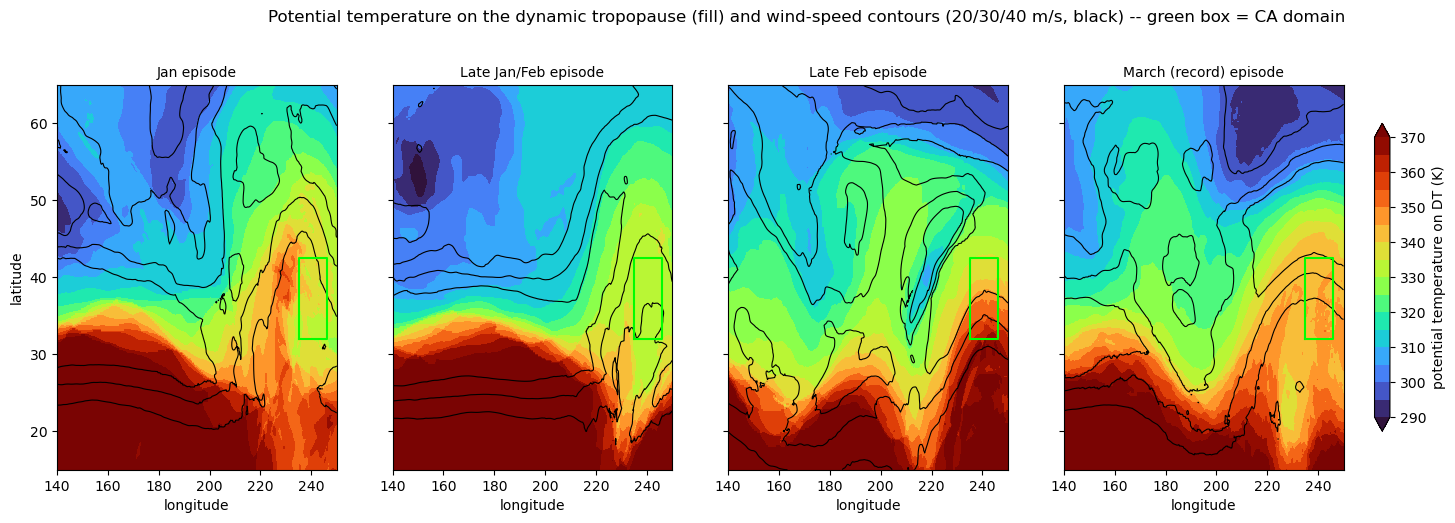

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
levels_theta = np.linspace(290, 370, 17)
for ax, row in zip(axes, z500_episodes.itertuples()):
    comp_theta = theta_dt.sel(time=slice(str(row.start_date), str(row.end_date))).mean(dim='time')
    comp_wind = wind_dt.sel(time=slice(str(row.start_date), str(row.end_date))).mean(dim='time')
    cf = ax.contourf(comp_theta.longitude, comp_theta.latitude, comp_theta, levels=levels_theta,
                      cmap='turbo', extend='both')
    ax.contour(comp_wind.longitude, comp_wind.latitude, comp_wind, levels=[20, 30, 40],
               colors='k', linewidths=0.8)
    ax.plot([235, 246, 246, 235, 235], [32, 32, 42.5, 42.5, 32], color='lime', lw=1.5)
    ax.set_title(row.label, fontsize=10)
    ax.set_xlabel('longitude')
axes[0].set_ylabel('latitude')
fig.colorbar(cf, ax=axes, shrink=0.8, label='potential temperature on DT (K)', pad=0.02)
plt.suptitle('Potential temperature on the dynamic tropopause (fill) and wind-speed contours '
             '(20/30/40 m/s, black) -- green box = CA domain', y=1.03)
plt.show()


## 4. DT Hovmoller diagrams: meridional wind and theta deviation from zonal mean

Reproduces the paper's clearest "block" diagnostic -- a near-stationary (not
eastward-propagating) feature at a fixed longitude band over many days is the
signature of blocking, as opposed to a normal progressive Rossby wave train. 25-45N
cosine-weighted mean, same latitude band the paper uses. Scope note: Davis's own figure
focuses specifically on the March 11-20 window; this version spans the four episodes'
combined date range (Jan 10 - Mar 29, bounded by their earliest start and latest end --
April itself isn't shown, since no WY2026 episode falls there) so all four are visible
side by side, not just the record one -- a deliberate generalization from the source
figure, not a reproduction of it.

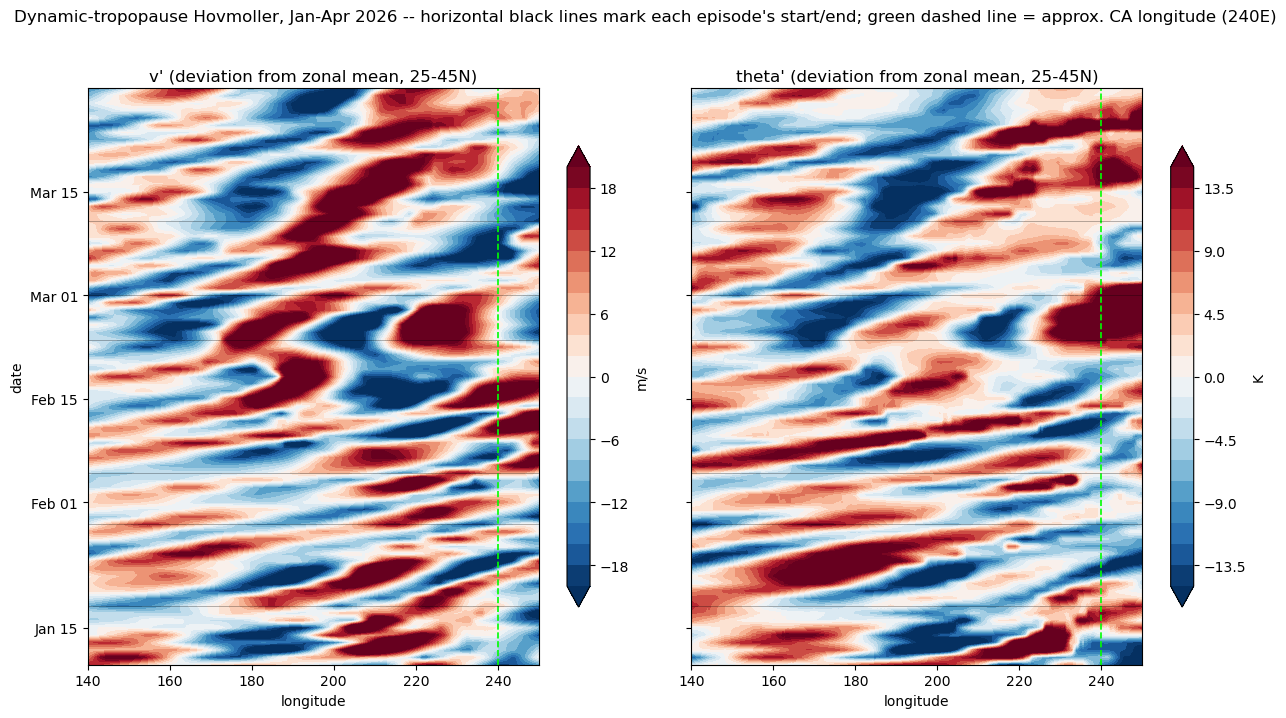

In [5]:
lat_mask = (theta_dt.latitude >= 25) & (theta_dt.latitude <= 45)
w = np.cos(np.deg2rad(theta_dt.latitude.where(lat_mask)))

theta_band = theta_dt.where(lat_mask).weighted(w.fillna(0)).mean(dim='latitude')
v_band = v_dt.where(lat_mask).weighted(w.fillna(0)).mean(dim='latitude')

theta_prime = theta_band - theta_band.mean(dim='longitude')
v_prime = v_band - v_band.mean(dim='longitude')

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
t0, t1 = str(z500_episodes.start_date.min()), str(z500_episodes.end_date.max())
vp = v_prime.sel(time=slice(t0, t1))
tp = theta_prime.sel(time=slice(t0, t1))

cf0 = axes[0].contourf(vp.longitude, vp.time, vp, levels=np.linspace(-20, 20, 21), cmap='RdBu_r', extend='both')
axes[0].set_title("v' (deviation from zonal mean, 25-45N)")
axes[0].set_xlabel('longitude')
axes[0].set_ylabel('date')
fig.colorbar(cf0, ax=axes[0], shrink=0.8, label='m/s')

cf1 = axes[1].contourf(tp.longitude, tp.time, tp, levels=np.linspace(-15, 15, 21), cmap='RdBu_r', extend='both')
axes[1].set_title("theta' (deviation from zonal mean, 25-45N)")
axes[1].set_xlabel('longitude')
fig.colorbar(cf1, ax=axes[1], shrink=0.8, label='K')

for ax in axes:
    ax.axvline(240, color='lime', lw=1.2, ls='--')  # approx CA longitude for reference
    for row in z500_episodes.itertuples():
        ax.axhline(pd.Timestamp(row.start_date), color='k', lw=0.5, alpha=0.4)
        ax.axhline(pd.Timestamp(row.end_date), color='k', lw=0.5, alpha=0.4)
axes[0].yaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
plt.suptitle('Dynamic-tropopause Hovmoller, Jan-Apr 2026 -- horizontal black lines mark each '
             'episode\'s start/end; green dashed line = approx. CA longitude (240E)', y=1.02)
plt.tight_layout()
plt.show()


## 5. Quantifying the wave-stalling: phase-speed estimate

Section 4's conclusion called the near-vertical band in the Hovmoller "textbook
blocking" based on a visual read alone -- flagged at the time as needing a real
measurement before being trusted. Three methods were tried, in order of increasing
robustness:

1. **Day-to-day peak tracking** (find the longitude of the theta' maximum each day,
   with a continuity window to avoid jumping between unrelated peaks): failed --
   the tracked peak repeatedly snapped to the domain's eastern edge (250E), a
   boundary artifact, not a real signal.
2. **Two-point lag cross-correlation** (correlate theta' time series at a fixed
   longitude pair, find the lag that maximizes correlation): unreliable -- weak
   correlations (0.07-0.59) and the resulting speed estimate flipped sign and
   magnitude depending on which arbitrary longitude pair was chosen.
3. **Whole-field 1-day-lag spatial cross-correlation scan** (for a grid of candidate
   phase speeds, shift the whole longitude profile by one day's worth of displacement
   at that speed and correlate against the next day's actual profile, using every
   interior longitude point at once): the method below -- far more stable, since it's
   not sensitive to any single point or pair.

In [6]:
from scipy.interpolate import interp1d

R_EARTH = 6.371e6


def mps_to_degperday(c_mps, lat=35.0):
    circumference_at_lat = 2 * np.pi * R_EARTH * np.cos(np.deg2rad(lat))
    return c_mps * 86400 / circumference_at_lat * 360


def lag1_phase_speed_scan(tp_sub, candidate_speeds_mps, interior_lon):
    """For each candidate phase speed, shift day t's profile eastward by that
    speed's one-day displacement and correlate against day t+1's actual profile,
    averaged over all days in the window and all interior longitude points at once.
    The speed that maximizes this average correlation is the best-fit phase speed."""
    lon = tp_sub.longitude.values
    vals = tp_sub.values
    mask = (lon >= interior_lon[0]) & (lon <= interior_lon[1])
    lon_interior = lon[mask]
    scores = []
    for c in candidate_speeds_mps:
        shift_deg = mps_to_degperday(c)
        corrs = []
        for t in range(vals.shape[0] - 1):
            f1 = interp1d(lon, vals[t + 1], kind='linear', bounds_error=False, fill_value=np.nan)
            day1_shifted = f1(lon_interior + shift_deg)
            day0_interior = vals[t][mask]
            valid = ~np.isnan(day1_shifted) & ~np.isnan(day0_interior)
            if valid.sum() < 5:
                continue
            corrs.append(np.corrcoef(day0_interior[valid], day1_shifted[valid])[0, 1])
        scores.append(np.nanmean(corrs) if corrs else np.nan)
    return np.array(scores)


theta_prime_record = theta_prime.sel(time=slice('2026-01-10', '2026-03-29'))
candidate_speeds = np.arange(-30, 30.1, 2.0)
sub_periods = {'Before March (Jan 10 - Mar 10)': ('2026-01-10', '2026-03-10'),
               'March episode (Mar 11-29)': ('2026-03-11', '2026-03-29')}
windows = {'full interior (150-240E)': (150, 240), 'narrow, centered on the visual feature (180-220E)': (180, 220)}

print('Best-fit eastward phase speed (m/s) and peak correlation, by period and window:\n')
for window_label, interior in windows.items():
    print(f'--- {window_label} ---')
    for period_label, (t0, t1) in sub_periods.items():
        sub = theta_prime_record.sel(time=slice(t0, t1))
        scores = lag1_phase_speed_scan(sub, candidate_speeds, interior)
        best_c = candidate_speeds[np.nanargmax(scores)]
        print(f'  {period_label} (n={sub.sizes["time"]}d): best c={best_c:+.0f} m/s, peak corr={np.nanmax(scores):.2f}')
    print()


Best-fit eastward phase speed (m/s) and peak correlation, by period and window:

--- full interior (150-240E) ---
  Before March (Jan 10 - Mar 10) (n=60d): best c=+6 m/s, peak corr=0.74
  March episode (Mar 11-29) (n=19d): best c=+6 m/s, peak corr=0.83

--- narrow, centered on the visual feature (180-220E) ---
  Before March (Jan 10 - Mar 10) (n=60d): best c=+6 m/s, peak corr=0.69


  March episode (Mar 11-29) (n=19d): best c=+4 m/s, peak corr=0.84



### Section 5 takeaway

**The wave-stalling impression does not survive quantification.** Both before-March
and the March episode itself best-fit to essentially the same eastward phase speed
(~4-6 m/s), in both the full-interior and the narrow window centered on the exact
feature that looked "stalled" by eye. If anything, March's fit is *cleaner* (higher
peak correlation, ~0.84 vs. ~0.68-0.74), meaning the wave was propagating just as
coherently -- at its normal speed -- during the record episode, not stuck in place.

**This retracts Section 4's conclusion, not just softens it.** What looked like a
near-vertical, stalled band in the Hovmoller was most likely an amplitude effect, not
a speed effect: March's anomaly was much larger (peak sigma 2.72 vs. ~1.9 for the
other three episodes), and a large, slowly-decaying bullseye sitting on top of an
otherwise-normally-translating wave can look "stuck" to the eye over a short window
even when the underlying wave hasn't slowed down at all. A genuine blocking-style
slowdown would show up here as a lower best-fit speed specifically in the March
window -- it doesn't.

**This also means `CA_2026_upstream_mechanism_composite.ipynb` Section 7's open
question is still open.** This notebook does not supply the differentiator that
Section 7 was unable to find. Across both upstream notebooks now, nothing tested so
far -- jet speed, NW Pacific ridging, onset-window IVT, or wave phase speed -- cleanly
explains why March persisted three times longer than its WY2026 predecessors. That is
itself a real, disclosable finding: the easy explanations don't hold up, and
resolving this would likely need Davis's own finer tools (trajectories, PV
non-conservation budgets) that neither upstream notebook in this project attempts.

## 6. Conclusion

**The dynamic-tropopause view gives a real, physically correct picture of the ridge
-- but the "textbook blocking" claim this notebook made on first pass (before
quantifying it in Section 5) did not survive measurement and has been retracted.**

- **Validation:** the 500-50 hPa level bracket is adequate -- 0% of all time/lat/lon
  points fail to find a 2-PVU crossing within it, and only 0.4% hit the degenerate
  below-500-hPa edge case (handled by the documented fallback). The DT-crossing
  search works as intended on real data, not just the synthetic test columns it was
  validated against beforehand.
- **Theta-on-DT maps (Section 3):** March shows the broadest, smoothest northward
  warm tongue (theta ~330-340 K reaching ~40-45N right at the CA box) of all four
  episodes -- a cleaner, more direct version of the "amplified ridge" signature than
  the fixed-300-hPa composite could show, since this tracks the actual tropopause
  surface rather than a fixed altitude. This part holds up: March's ridge is
  genuinely the most amplified, consistent with it being the record episode by
  construction.
- **The DT Hovmoller "wave-stalling" claim does not hold up (Section 5).** The
  near-vertical band that looked like blocking by eye turned out, once quantified
  with a whole-field phase-speed scan, to best-fit the *same* ~4-6 m/s eastward speed
  before and during the March episode -- with March's fit actually *cleaner*, not
  stalled. The visual impression was most likely driven by March's much larger
  anomaly amplitude (peak sigma 2.72 vs. ~1.9 for the other three), not a change in
  propagation speed. This is retracted, not just caveated.
- **The open question from `CA_2026_upstream_mechanism_composite.ipynb` Section 7
  remains open.** Across both upstream notebooks, nothing tested so far -- jet speed,
  NW Pacific ridging, onset-window IVT, or now wave phase speed -- provides a clean
  discriminator for why March persisted three times longer than its WY2026
  predecessors. That absence of an easy answer is itself the most honest finding
  this pair of notebooks has produced.

**Caveats:**
- **n=1 still applies.** One record episode, no historical DT climatology to compare
  against, exactly as flagged in the intro.
- **The single-crossing DT algorithm's limitation (noted in Section 2) is untested
  here** -- diabatic PV reduction in a frontal zone, which Davis's own paper
  describes as actually happening during this event, could in principle produce a
  shallow false crossing. Not checked for in this pass.
- **Davis's trajectory and PV-non-conservation analysis (his Figs. 9-12) is still not
  attempted.** Given the phase-speed scan ruled out the simplest "it just slowed
  down" explanation, those finer diagnostics -- which can distinguish diabatic
  ridge-building from pure advection -- are now the more clearly motivated next step,
  rather than an alternative to a question this notebook already answered.